# Systemy AI – Laboratorium 5
## Zadanie: który klasyfikator najlepiej rozpoznaje cukrzycę?

Zbiór **Pima Indians Diabetes**: 768 kobiet z plemienia Pima (Arizona, USA). Zadanie: na podstawie wyników badań przewidzieć, czy u pacjentki zdiagnozowano cukrzycę w ciągu 5 lat (`outcome` = 1).

Wykonaj całą procedurę z notatnika `SystemyAI_Lab5_Titanic_CV.ipynb`: porównaj klasyfikatory walidacją krzyżową, dostrój hiperparametry, wybierz najlepszy model i **dopiero na końcu, raz**, oceń go na zbiorze testowym. Cały kod piszesz sam(a).

| Kolumna | Znaczenie |
|---|---|
| `pregnancies` | liczba ciąż |
| `glucose` | stężenie glukozy po 2 h w doustnym teście obciążenia glukozą [mg/dl] |
| `blood_pressure` | ciśnienie rozkurczowe [mm Hg] |
| `skin_thickness` | grubość fałdu skórnego na tricepsie [mm] |
| `insulin` | stężenie insuliny po 2 h [μU/ml] |
| `bmi` | wskaźnik masy ciała [kg/m²] |
| `pedigree` | wskaźnik obciążenia rodzinnego cukrzycą |
| `age` | wiek [lata] |
| `outcome` | **etykieta**: 1 = cukrzyca, 0 = brak |

**Zasady** (jak poprzednio): nazwy zmiennych z treści są obowiązkowe; komórek `# TEST` nie zmieniaj; przed oddaniem *Uruchom ponownie i uruchom wszystko*.

---
## 1. Wczytanie danych
Plik nie ma wiersza nagłówka, więc nazwy kolumn trzeba podać samemu:

```python
URL = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
kolumny = ["pregnancies", "glucose", "blood_pressure", "skin_thickness",
           "insulin", "bmi", "pedigree", "age", "outcome"]
df = pd.read_csv(URL, names=kolumny)
```
Zaimportuj potrzebne biblioteki, wczytaj dane do `df` i obejrzyj je (`shape`, `head()`, `describe()`).

In [35]:
# Twoje rozwiązanie
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_val_score,
                                     validation_curve, GridSearchCV)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.pipeline import Pipeline




URL = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
kolumny = ["pregnancies", "glucose", "blood_pressure", "skin_thickness",
           "insulin", "bmi", "pedigree", "age", "outcome"]
df = pd.read_csv(URL, names=kolumny)

print(df.shape)
print(df.head())
print(df.describe())

(768, 9)
   pregnancies  glucose  blood_pressure  skin_thickness  insulin   bmi  \
0            6      148              72              35        0  33.6   
1            1       85              66              29        0  26.6   
2            8      183              64               0        0  23.3   
3            1       89              66              23       94  28.1   
4            0      137              40              35      168  43.1   

   pedigree  age  outcome  
0     0.627   50        1  
1     0.351   31        0  
2     0.672   32        1  
3     0.167   21        0  
4     2.288   33        1  
       pregnancies     glucose  blood_pressure  skin_thickness     insulin  \
count   768.000000  768.000000      768.000000      768.000000  768.000000   
mean      3.845052  120.894531       69.105469       20.536458   79.799479   
std       3.369578   31.972618       19.355807       15.952218  115.244002   
min       0.000000    0.000000        0.000000        0.000000    

In [36]:
# TEST
assert df.shape == (768, 9) and list(df.columns)[-1] == "outcome"
print("1 OK")

1 OK


---
## 2. EDA i ukryte braki
1. `class_share` – udział każdej klasy w `outcome`.
2. `df.isna().sum()` – czy są braki? Teraz policz `zeros` – liczbę **zer** w każdej kolumnie cech.
3. Narysuj `fig, axes = plt.subplots(1, 2, figsize=(12, 5))`: po lewej histogram `glucose`, po prawej histogram `insulin`, oba z kolorem według `outcome` (`sns.histplot(..., hue="outcome")`).

pregnancies       0
glucose           0
blood_pressure    0
skin_thickness    0
insulin           0
bmi               0
pedigree          0
age               0
outcome           0
dtype: int64

 pregnancies       111
glucose             5
blood_pressure     35
skin_thickness    227
insulin           374
bmi                11
pedigree            0
age                 0
outcome           500
dtype: int64

 outcome
0    0.651042
1    0.348958
Name: proportion, dtype: float64


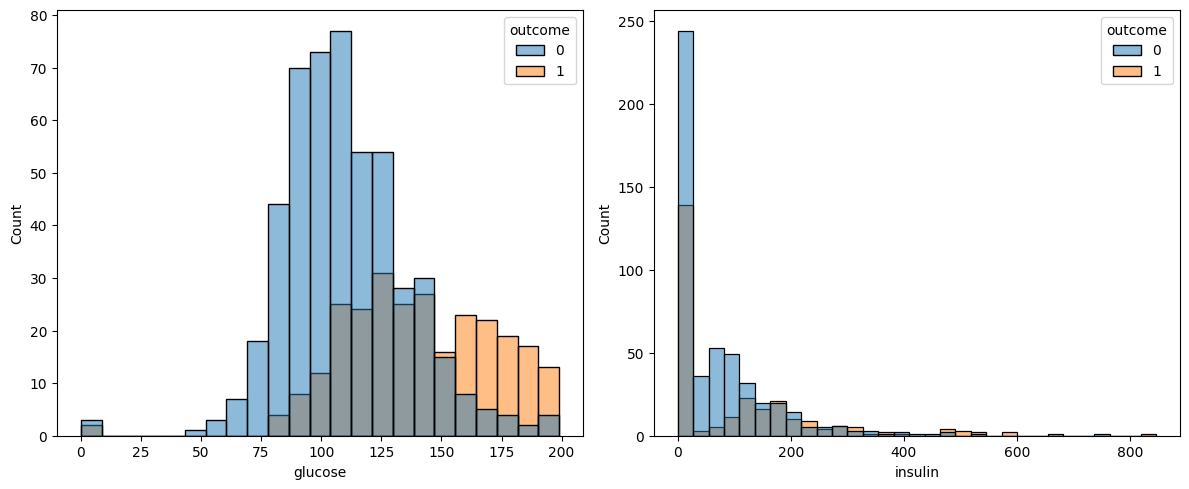

In [37]:
# Twoje rozwiązanie
class_share = df["outcome"].value_counts(normalize=True)
print(df.isna().sum())
zeros = (df == 0).sum()
print("\n",zeros)
print("\n", class_share)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.histplot(data=df, x="glucose", hue="outcome", ax=axes[0])
sns.histplot(data=df, ax=axes[1], hue="outcome", x="insulin")
plt.tight_layout()
plt.show()


In [38]:
# TEST
assert abs(class_share[0] - 0.651) < 1e-3
assert zeros["insulin"] == 374 and zeros["glucose"] == 5 and zeros["pregnancies"] == 111
print("2 OK")

2 OK


*Twoja odpowiedź:*
1. Jaką accuracy osiągnie baseline?
2. W których kolumnach zero jest **fizycznie niemożliwe** (żyjący człowiek nie może mieć takiej wartości), a w której jest zupełnie normalne?
3. Która cecha najwyraźniej różni chore i zdrowe pacjentki?

1. Baseline osiagnie accuracy na poziomie ~65,1%.
2. Zera są niemożliwe w kolumnach: blood_pressure, bmi, glucose, insulin i skin_thickness
3. Cechą, która rózni zdorwe i chore pacjentki to glucose

---
## 3. Zamiana ukrytych braków na `NaN`
W kolumnach `glucose`, `blood_pressure`, `skin_thickness`, `insulin`, `bmi` zamień zera na `np.nan` (`replace(0, np.nan)`). Wynik zapisz w `df_clean` (kopia `df`), a liczbę braków w każdej kolumnie w `missing`.

Model nie wie, że zero oznacza brak. Dla niego „insulina = 0” to po prostu bardzo niska insulina – a takich „pomiarów” jest prawie połowa.

In [39]:
# Twoje rozwiązanie
cols = ["glucose", "blood_pressure", "skin_thickness", "insulin", "bmi"]
df_clean = df.copy()
df_clean[cols] = df[cols].replace(0,np.nan)
missing = df_clean.isna().sum()
print(missing)

pregnancies         0
glucose             5
blood_pressure     35
skin_thickness    227
insulin           374
bmi                11
pedigree            0
age                 0
outcome             0
dtype: int64


In [40]:
# TEST
assert missing["insulin"] == 374 and missing["skin_thickness"] == 227 and missing["pregnancies"] == 0
assert (df["insulin"] == 0).sum() == 374, "Nie zmieniaj oryginalnego df - użyj copy()"
print("3 OK")

3 OK


*Twoja odpowiedź:* insuliny brakuje u prawie połowy pacjentek. Jakie masz możliwości? Co wybierasz i dlaczego?

Możliwe opcje to: usuniecię wierszy z brakami, uzupełnienie braków (średnią, medianą lub algorytmem np. KNNImputer), usunięcie komulny insulin.
W moim mniemaniu najlepszą opcją jest wybranie uzupelnienie brakow imputacją zaawansowaną. Mediana lub średnia nie dałaby satysfakcjonujacych danych, a KNN imputer oszacuje sobie brakujaca insuline na podstawie podobnych parametrow u innych pacjentek.


---
## 4. Podział i przygotowanie
1. `X` – wszystkie cechy z `df_clean`, `y` – `outcome`. Podziel na `X_train, X_test, y_train, y_test` (`test_size=0.25`, `stratify=y`, `random_state=42`).
2. Napisz funkcję `model_z(klasyfikator)`, która zwraca pipeline: `SimpleImputer(strategy="median")` → `StandardScaler()` → klasyfikator. (Wszystkie cechy są liczbowe, więc `ColumnTransformer` nie jest potrzebny.)
3. Utwórz `cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)`.

In [41]:
# Twoje rozwiązanie
X = df_clean.drop(columns=['outcome'])
y = df_clean['outcome']

X_train, X_test, y_train, y_test = train_test_split(
  X, y, test_size=0.25, stratify=y, random_state=42
)

def model_z(klasyfikator):
  return Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('classifier', klasyfikator),
  ])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [42]:
# TEST
assert X_train.shape == (576, 8) and X_test.shape == (192, 8)
assert X_train["insulin"].isna().sum() > 0, "Podział robimy na df_clean (z NaN zamiast zer)"
assert len(model_z(None).steps) == 3
print("4 OK")

4 OK


---
## 5. Porównanie klasyfikatorów walidacją krzyżową
Dla pięciu modeli z domyślnymi hiperparametrami: `DummyClassifier(strategy="most_frequent")`, `LogisticRegression()`, `KNeighborsClassifier()`, `DecisionTreeClassifier(random_state=42)`, `RandomForestClassifier(random_state=42)` policz `cross_val_score` na zbiorze treningowym i accuracy na całym zbiorze treningowym.

Zbierz wyniki w tabeli `porownanie` (indeks: `"baseline"`, `"regresja logistyczna"`, `"kNN"`, `"drzewo decyzyjne"`, `"las losowy"`; kolumny: `"CV średnia"`, `"CV odch."`, `"train"`) i narysuj wykres słupkowy średnich z odchyleniami.

                      CV średnia  CV odch.     train
baseline                0.651049  0.002249  0.651042
regresja logistyczna    0.777856  0.024709  0.789931
kNN                     0.736132  0.020716  0.835069
drzewo decyzyjne        0.713568  0.024244  1.000000
las losowy              0.748291  0.014015  1.000000


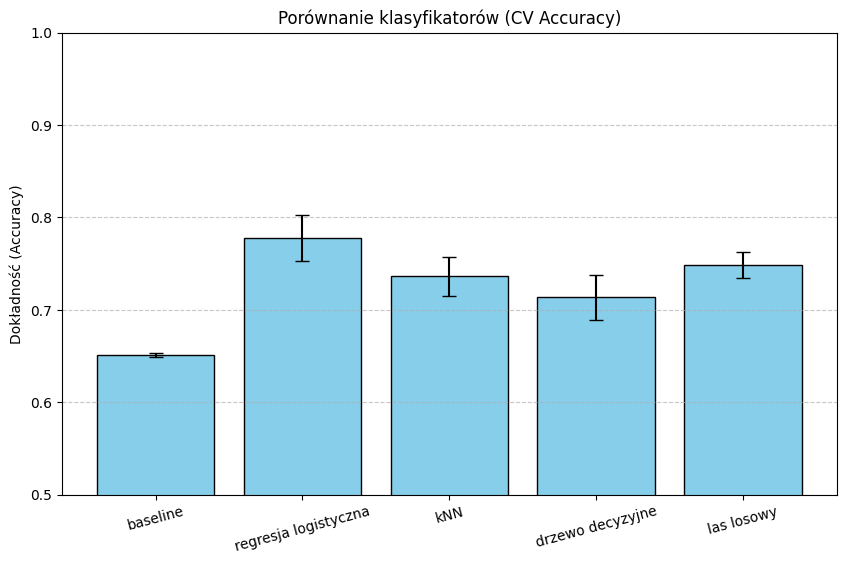

In [43]:
# Twoje rozwiązanie
models = {
    "baseline": DummyClassifier(strategy="most_frequent"),
    "regresja logistyczna": LogisticRegression(),
    "kNN": KNeighborsClassifier(),
    "drzewo decyzyjne": DecisionTreeClassifier(random_state=42),
    "las losowy": RandomForestClassifier(random_state=42)
}

results = []
for name, clf in models.items():
  pipe = model_z(clf)

  cv_scores = cross_val_score(
    pipe, X_train, y_train, cv=cv, scoring='accuracy'
  )
  cv_mean = cv_scores.mean()
  cv_std = cv_scores.std()

  pipe.fit(X_train, y_train)
  train_acc = pipe.score(X_train, y_train)

  results.append({
    'CV średnia': cv_mean,
    'CV odch.': cv_std,
    'train': train_acc,
  })

porownanie = pd.DataFrame(
  results,
  index=[
    'baseline',
    'regresja logistyczna',
    'kNN',
    'drzewo decyzyjne',
    'las losowy',
  ],
)

print(porownanie)
plt.figure(figsize=(10, 6))
plt.bar(porownanie.index, porownanie["CV średnia"], yerr=porownanie["CV odch."], capsize=5, color="skyblue", edgecolor="black")
plt.title("Porównanie klasyfikatorów (CV Accuracy)")
plt.ylabel("Dokładność (Accuracy)")
plt.ylim(0.5, 1.0)
plt.xticks(rotation=15)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

In [44]:
# TEST
assert list(porownanie.index) == ["baseline", "regresja logistyczna", "kNN", "drzewo decyzyjne", "las losowy"]
assert abs(porownanie.loc["baseline", "CV średnia"] - 0.651) < 1e-2
assert abs(porownanie.loc["regresja logistyczna", "CV średnia"] - 0.778) < 1e-2
assert porownanie.loc["drzewo decyzyjne", "train"] > 0.99
print("5 OK")

5 OK


---
## 6. Krzywa walidacji dla kNN
Policz `validation_curve` dla `kneighborsclassifier__n_neighbors` w `ks = [1, 3, 5, 7, 11, 15, 21, 31, 51]`. Wyniki zapisz w `tren`, `walid`; narysuj średnie (trening i walidacja) w funkcji k.

Średnie wyniki na zbiorze treningowym (tren): [[1.         1.         1.         1.         1.        ]
 [0.8673913  0.86334056 0.88503254 0.85249458 0.83947939]
 [0.85217391 0.8373102  0.84815618 0.82863341 0.83947939]
 [0.81956522 0.84381779 0.84598698 0.81778742 0.80694143]
 [0.82608696 0.82429501 0.82646421 0.79826464 0.80477223]
 [0.80869565 0.80043384 0.8308026  0.79392625 0.80694143]
 [0.80434783 0.80477223 0.80694143 0.79609544 0.79392625]
 [0.78695652 0.76572668 0.78958785 0.78958785 0.78308026]
 [0.76304348 0.76572668 0.77006508 0.77874187 0.76355748]]
Średnie wyniki na zbiorze walidacyjnym (walid): [[0.6637931  0.67826087 0.70434783 0.67826087 0.72173913]
 [0.71551724 0.73913043 0.66956522 0.76521739 0.7826087 ]
 [0.72413793 0.74782609 0.70434783 0.73913043 0.76521739]
 [0.75       0.73043478 0.71304348 0.74782609 0.75652174]
 [0.76724138 0.76521739 0.73043478 0.79130435 0.8       ]
 [0.75862069 0.76521739 0.73043478 0.8        0.83478261]
 [0.75       0.76521739 0.74782609 

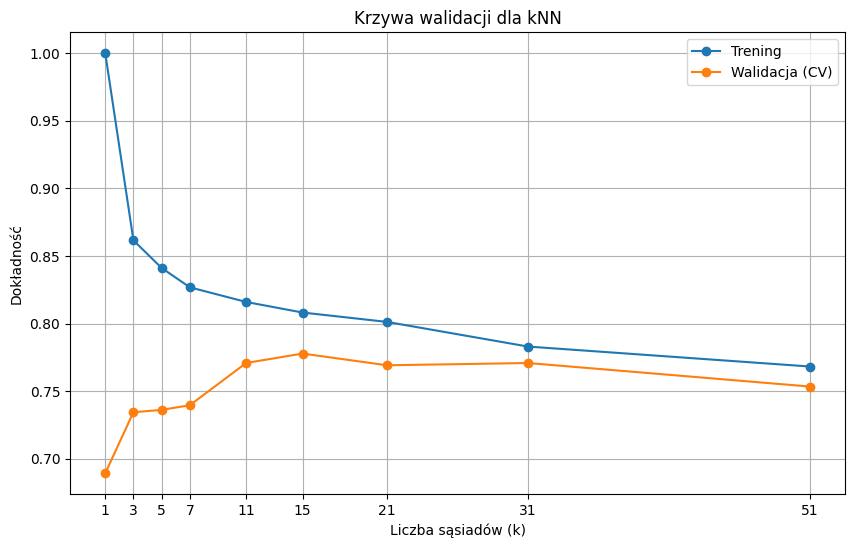

In [45]:
# Twoje rozwiązanie

knn_pipe = model_z(KNeighborsClassifier())

train_scores, valid_scores = validation_curve(
  knn_pipe,
  X_train,
  y_train,
  param_name='classifier__n_neighbors',
  param_range=ks,
  cv=cv,
  scoring='accuracy',
)

tren = train_scores
walid = valid_scores

print('Średnie wyniki na zbiorze treningowym (tren):', tren)
print('Średnie wyniki na zbiorze walidacyjnym (walid):', walid)

plt.figure(figsize=(10, 6))
plt.plot(ks, tren.mean(axis=1), label="Trening", marker="o")
plt.plot(ks, walid.mean(axis=1), label="Walidacja (CV)", marker="o")
plt.title("Krzywa walidacji dla kNN")
plt.xlabel("Liczba sąsiadów (k)")
plt.ylabel("Dokładność")
plt.xticks(ks)
plt.legend()
plt.grid(True)
plt.show()

In [46]:
# TEST
assert tren.shape == (9, 5) and walid.shape == (9, 5)
assert tren.mean(axis=1)[0] == 1.0, "Dla k=1 wynik treningowy powinien wynosić 1.0"
print("6 OK")

6 OK


*Twoja odpowiedź:* dlaczego dla k = 1 wynik treningowy wynosi dokładnie 1.0? Gdzie jest przeuczenie, a gdzie niedouczenie?

dla k=1 klasyfikator szukajac najblizszego sasiada dla punktu w zbiorze treningowym znajduje "sam siebie".

Przeuczenie wystepuje dla malych wartosci 1,3; tam gdzie roznica miedzy zbiorem treningowym a zbiorem testowym jest znaczna. Niedouczenie pojawia sie zas na wartosciach duzych (np. 51).

---
## 7. Strojenie: `GridSearchCV`
Dla każdego z czterech klasyfikatorów uruchom `GridSearchCV(model_z(...), siatka, cv=cv)` na zbiorze treningowym. Siatki:
- regresja logistyczna: `C` ∈ {0.01, 0.1, 1, 10, 100},
- kNN: `n_neighbors` ∈ {1, 3, 5, 7, 11, 15, 21, 31},
- drzewo: `max_depth` ∈ {2, 3, 4, 5, 6, 8, None},
- las losowy: `max_depth` ∈ {3, 5, 8, None}, `n_estimators` ∈ {100, 300}.

Nauczone obiekty zapisz w słowniku `wyniki_gs` (klucze jak w punkcie 5, bez baseline'u) i wypisz najlepsze parametry oraz `best_score_` każdego modelu.

In [47]:
# Twoje rozwiązanie

grids = {
  'regresja logistyczna': {
    'estimator': LogisticRegression(random_state=42),
    'param_grid': {'classifier__C': [0.01, 0.1, 1, 10, 100]},
  },
  'kNN': {
    'estimator': KNeighborsClassifier(),
    'param_grid': {
      'classifier__n_neighbors': [1, 3, 5, 7, 11, 15, 21, 31]
    },
  },
  'drzewo decyzyjne': {
    'estimator': DecisionTreeClassifier(random_state=42),
    'param_grid': {'classifier__max_depth': [2, 3, 4, 5, 6, 8, None]},
  },
  'las losowy': {
    'estimator': RandomForestClassifier(random_state=42),
    'param_grid': {
      'classifier__max_depth': [3, 5, 8, None],
      'classifier__n_estimators': [100, 300],
    },
  },
}

wyniki_gs = {}
for name, config in grids.items():
  pipe = model_z(config['estimator'])

  gs = GridSearchCV(
    estimator=pipe,
    param_grid=config['param_grid'],
    cv=cv,
    scoring='accuracy',
    n_jobs=-1,
  )

  gs.fit(X_train, y_train)

  wyniki_gs[name] = gs

  print(f"{name}:")
  print(f"  Najlepsze parametry: {gs.best_params_}")
  print(f"  Najlepszy wynik (CV Accuracy): {gs.best_score_:.4f}\n")

regresja logistyczna:
  Najlepsze parametry: {'classifier__C': 1}
  Najlepszy wynik (CV Accuracy): 0.7779

kNN:
  Najlepsze parametry: {'classifier__n_neighbors': 15}
  Najlepszy wynik (CV Accuracy): 0.7778

drzewo decyzyjne:
  Najlepsze parametry: {'classifier__max_depth': 5}
  Najlepszy wynik (CV Accuracy): 0.7500

las losowy:
  Najlepsze parametry: {'classifier__max_depth': 3, 'classifier__n_estimators': 300}
  Najlepszy wynik (CV Accuracy): 0.7622



In [48]:
# TEST
assert set(wyniki_gs) == {"regresja logistyczna", "kNN", "drzewo decyzyjne", "las losowy"}
assert all(hasattr(gs, "best_estimator_") for gs in wyniki_gs.values())
assert all(gs.best_score_ > 0.7 for gs in wyniki_gs.values())
print("7 OK")

7 OK


---
## 8. Wybór modelu i ocena końcowa
1. `najlepszy` – nazwa modelu z najwyższym `best_score_`; `model_koncowy` – jego `best_estimator_`.
2. `acc_test` – accuracy `model_koncowy` na zbiorze testowym (**jedyny raz, kiedy używasz `X_test`**).
3. Macierz pomyłek (`ConfusionMatrixDisplay`) i `classification_report`.

Najlepszy model: regresja logistyczna
Wynik CV najlepszego modelu: 0.7779

Accuracy na zbiorze testowym: 0.7240

Raport klasyfikacji na zbiorze testowym:
              precision    recall  f1-score   support

           0       0.76      0.84      0.80       125
           1       0.63      0.51      0.56        67

    accuracy                           0.72       192
   macro avg       0.70      0.67      0.68       192
weighted avg       0.72      0.72      0.72       192



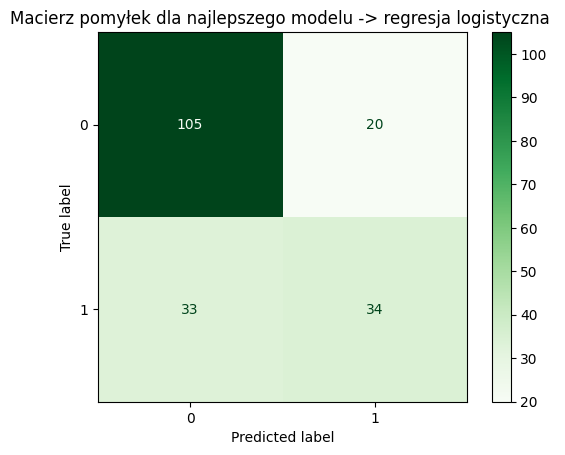

In [49]:
# Twoje rozwiązanie
najlepszy = max(wyniki_gs, key=lambda n: wyniki_gs[n].best_score_)
model_koncowy = wyniki_gs[najlepszy].best_estimator_
print(f"Najlepszy model: {najlepszy}")
print(f"Wynik CV najlepszego modelu: {wyniki_gs[najlepszy].best_score_:.4f}\n")
acc_test = model_koncowy.score(X_test, y_test)
print(f"Accuracy na zbiorze testowym: {acc_test:.4f}\n")
y_pred = model_koncowy.predict(X_test)
print("Raport klasyfikacji na zbiorze testowym:")
print(classification_report(y_test, y_pred))
ConfusionMatrixDisplay.from_estimator(model_koncowy, X_test, y_test, cmap="Greens")
plt.title(f"Macierz pomyłek dla najlepszego modelu -> {najlepszy} ")
plt.show()

In [50]:
# TEST
assert najlepszy == max(wyniki_gs, key=lambda n: wyniki_gs[n].best_score_)
assert 0.65 < acc_test < 0.9
print("8 OK")

8 OK


*Twoja odpowiedź:*
1. Jak wynik testowy ma się do szacunku z walidacji krzyżowej? Czy różnica cię niepokoi? (Zbiór testowy ma 192 pacjentki – ile p.p. to jedna osoba?)
2. Jaki jest recall dla klasy „cukrzyca”? Co oznacza on dla pacjentek? Czy accuracy to dobra metryka do wyboru modelu w tym zastosowaniu?
3. Modele w czołówce różnią się w CV o 1–2 p.p., a odchylenia wynoszą ok. 2–3 p.p. Czy można jednoznacznie wskazać „najlepszy” algorytm?



1. Wynik testowy jest zblizony do walidacji krzyzowej. Rożnica mnie nie niepokoi, 1 osoba to zaledwie 0.52 p.p.
2. Recall wynosi 51%. Oznacza to ze model wykrywa polowe chorob. Accuracy to nie najlepsza metryak poniewaz zbior nie jest zbalansowany. Więc lepiej byloby sie kierowac metrykami takimi jak recall lub f1 score
3. Roznice na poziomie 1 lub 2 p.p przy odchyleniu ~3p.p wiec roznice sa niewielkie. Oznacza to ze najlepiej wybrac model najprostszy.

---
## 9. Dla chętnych
1. Powtórz punkty 7–8 z `scoring="recall"` w `GridSearchCV`. Czy zmienił się wybrany model? Co stało się z precision?
2. Dodaj do imputera `add_indicator=True` (flagi braków). Czy sam fakt braku pomiaru insuliny niesie informację?
3. Sprawdź, jak wyglądałyby wyniki, gdyby zostawić zera zamiast `NaN` (punkt 3 pominięty). Czy różnica jest duża? Dlaczego może być mała?